<a href="https://colab.research.google.com/github/Rachel-210/Atividade-05-Revisao_CD/blob/main/Revisao14_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exercício 1 - Valores Ausentes

In [ ]:
# IMPORTAÇÕES
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno
from sklearn.impute import KNNImputer

In [82]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# CARREGAMENTO DOS DADOS
df = pd.read_csv('/content/drive/MyDrive/melb_data.csv')

In [ ]:
df

,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,...,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Lattitude,Longtitude,Regionname,Propertycount
0,Abbotsford,85 Turner St,2,h,1480000.0,S,Biggin,3/12/2016,2.5,3067.0,...,1.0,1.0,202.0,NaN,NaN,Yarra,-37.79960,144.99840,Northern Metropolitan,4019.0
1,Abbotsford,25 Bloomburg St,2,h,1035000.0,S,Biggin,4/02/2016,2.5,3067.0,...,1.0,0.0,156.0,79.0,1900.0,Yarra,-37.80790,144.99340,Northern Metropolitan,4019.0
2,Abbotsford,5 Charles St,3,h,1465000.0,SP,Biggin,4/03/2017,2.5,3067.0,...,2.0,0.0,134.0,150.0,1900.0,Yarra,-37.80930,144.99440,Northern Metropolitan,4019.0
3,Abbotsford,40 Federation La,3,h,850000.0,PI,Biggin,4/03/2017,2.5,3067.0,...,2.0,1.0,94.0,NaN,NaN,Yarra,-37.79690,144.99690,Northern Metropolitan,4019.0
4,Abbotsford,55a Park St,4,h,1600000.0,VB,Nelson,4/06/2016,2.5,3067.0,...,1.0,2.0,120.0,142.0,2014.0,Yarra,-37.80720,144.99410,Northern Metropolitan,4019.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13575,Wheelers Hill,12 Strada Cr,4,h,1245000.0,S,Barry,26/08/2017,16.7,3150.0,...,2.0,2.0,652.0,NaN,1981.0,NaN,-37.90562,145.16761,South-Eastern Metropolitan,7392.0
13576,Williamstown,77 Merrett Dr,3,h,1031000.0,SP,Williams,26/08/2017,6.8,3016.0,...,2.0,2.0,333.0,133.0,1995.0,NaN,-37.85927,144.87904,Western Metropolitan,6380.0
13577,Williamstown,83 Power St,3,h,1170000.0,S,Raine,26/08/2017,6.8,3016.0,...,2.0,4.0,436.0,NaN,1997.0,NaN,-37.85274,144.88738,Western Metropolitan,6380.0
13578,Williamstown,96 Verdon St,4,h,2500000.0,PI,Sweeney,26/08/2017,6.8,3016.0,...,1.0,5.0,866.0,157.0,1920.0,NaN,-37.85908,144.89299,Western Metropolitan,6380.0


In [ ]:
# DIAGNÓSTICO INICIAL
print(f"Linhas: {df.shape[0]} | Colunas: {df.shape[1]}")
print(df.info())

Linhas: 13580 | Colunas: 21
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13580 entries, 0 to 13579
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Suburb         13580 non-null  object 
 1   Address        13580 non-null  object 
 2   Rooms          13580 non-null  int64  
 3   Type           13580 non-null  object 
 4   Price          13580 non-null  float64
 5   Method         13580 non-null  object 
 6   SellerG        13580 non-null  object 
 7   Date           13580 non-null  object 
 8   Distance       13580 non-null  float64
 9   Postcode       13580 non-null  float64
 10  Bedroom2       13580 non-null  float64
 11  Bathroom       13580 non-null  float64
 12  Car            13518 non-null  float64
 13  Landsize       13580 non-null  float64
 14  BuildingArea   7130 non-null   float64
 15  YearBuilt      8205 non-null   float64
 16  CouncilArea    12211 non-null  object 
 17  Lattitude      13580 n

In [ ]:
# RESUMO DE VALORES AUSENTES (QUANTIDADE E %)
total_linhas = len(df)
qtd_nulos = df.isnull().sum()
perc_nulos = (df.isnull().mean() * 100)

df_resumo_ausencias = pd.DataFrame({
    'Total_Ausentes': qtd_nulos,
    'Percentual_%': perc_nulos
})

df_resumo_ausencias = df_resumo_ausencias[df_resumo_ausencias['Total_Ausentes'] > 0]
df_resumo_ausencias = df_resumo_ausencias.sort_values(by='Total_Ausentes', ascending=False)

print(df_resumo_ausencias)

              Total_Ausentes  Percentual_%
BuildingArea            6450     47.496318
YearBuilt               5375     39.580265
CouncilArea             1369     10.081001
Car                       62      0.456554


<Figure size 1000x500 with 0 Axes>

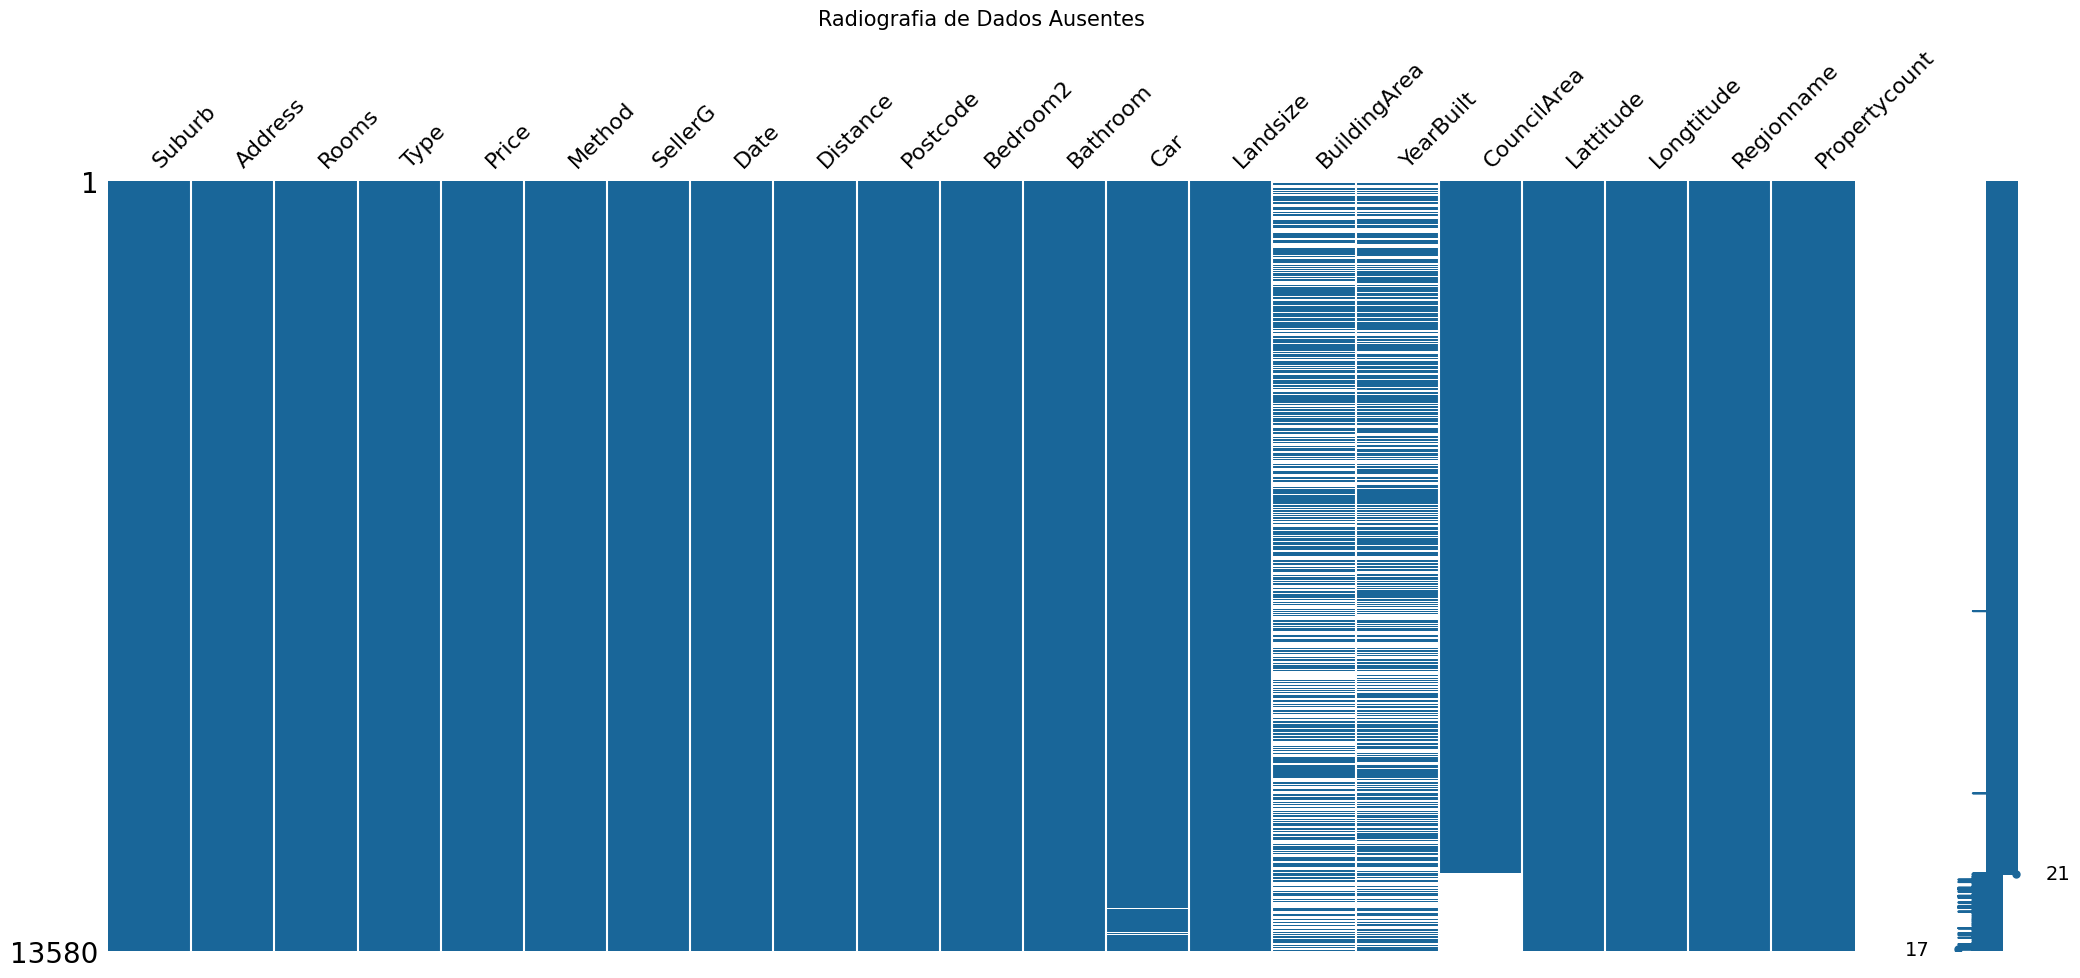

In [ ]:
# VISUALIZAÇÃO DO PADRÃO DE AUSÊNCIA
plt.figure(figsize=(10, 5))
msno.matrix(df, color=(0.1, 0.4, 0.6))
plt.title("Radiografia de Dados Ausentes", fontsize=15, pad=15)
plt.show()

<Figure size 1000x500 with 0 Axes>

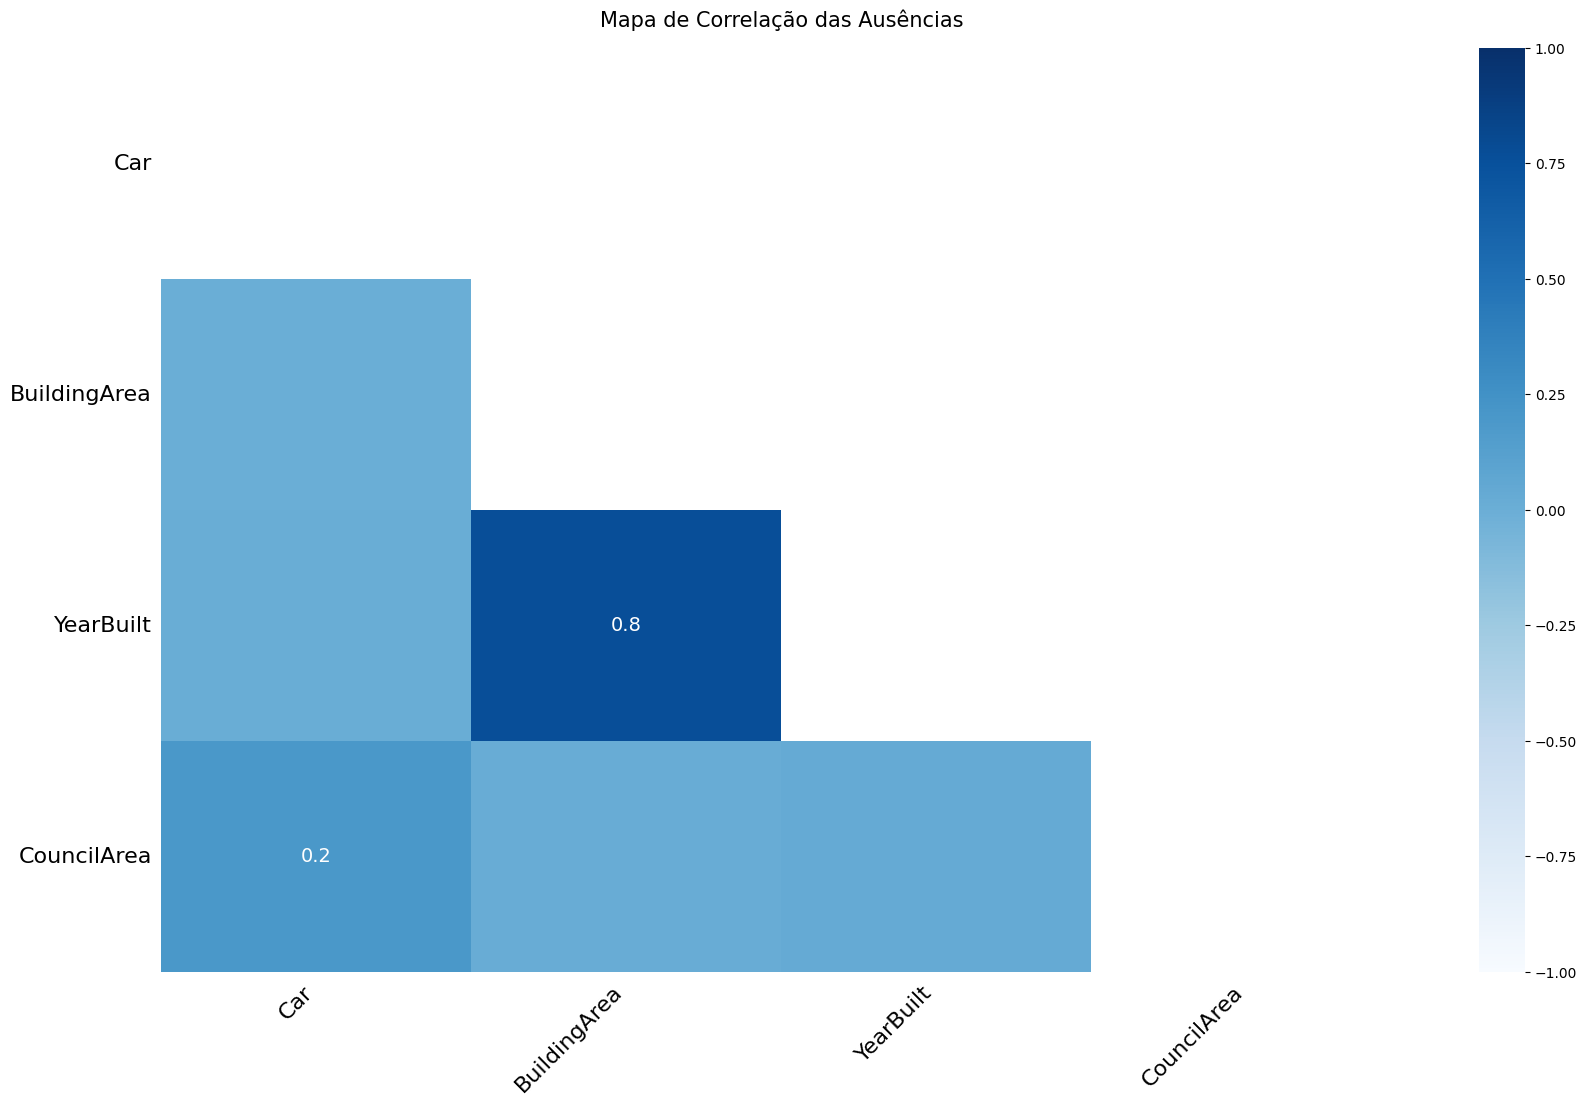

In [ ]:
plt.figure(figsize=(10, 5))
msno.heatmap(df, cmap="Blues")
plt.title("Mapa de Correlação das Ausências", fontsize=15, pad=15)
plt.show()

In [ ]:
# ESTRATÉGIA 1 — REMOÇÃO
df_remocao = df.copy()

# Justificativa: Variáveis com mais de 35% de lacunas comprometem a confiabilidade de qualquer modelagem.
# Optei por descartar colunas críticas vazias e, em seguida, removi as linhas remanescentes com nulos pontuais.
limiar_aceitavel = len(df_remocao) * 0.35
colunas_para_excluir = [coluna for coluna in df_remocao.columns if df_remocao[coluna].isnull().sum() > limiar_aceitavel]

df_remocao = df_remocao.drop(columns=colunas_para_excluir)
df_remocao = df_remocao.dropna()

In [ ]:
# ESTRATÉGIA 2 — IMPUTAÇÃO
df_imputacao = df.copy()

# Tratando colunas numéricas com a MEDIANA (mais segura contra distorções)
for coluna in df_imputacao.select_dtypes(include=[np.number]).columns:
    if df_imputacao[coluna].isnull().sum() > 0:
        mediana_col = df_imputacao[coluna].median()
        df_imputacao[coluna].fillna(mediana_col)

# Tratando colunas categóricas com a MODA (o valor mais frequente)
for coluna in df_imputacao.select_dtypes(include=['object']).columns:
    if df_imputacao[coluna].isnull().sum() > 0:
        moda_col = df_imputacao[coluna].mode()[0] if not df_imputacao[coluna].mode().empty else 'Indefinido'
        df_imputacao[coluna].fillna(moda_col)

In [ ]:
# COMPARAÇÃO ENTRE AS ESTRATÉGIAS
print(f"Dataset Original: {len(df)} linhas")
print(f"Remoção: {len(df_remocao)} linhas")
print(f"Imputação: {len(df_imputacao)} linhas")

# Analisando o comportamento de uma variável de destaque
variavel_alvo = 'BuildingArea' if 'BuildingArea' in df.columns else 'Landsize'

print(f"Original (sem nulos) — Média: {df[variavel_alvo].dropna().mean():.2f} | Mediana: {df[variavel_alvo].dropna().median():.2f}")

if variavel_alvo in df_remocao.columns:
    print(f"Remoção — Média: {df_remocao[variavel_alvo].mean():.2f} | Mediana: {df_remocao[variavel_alvo].median():.2f}")
else:
    print("Remoção — Coluna totalmente descartada.")

print(f"Imputação — Média: {df_imputacao[variavel_alvo].mean():.2f} | Mediana: {df_imputacao[variavel_alvo].median():.2f}")

Dataset Original: 13580 linhas
Remoção: 12211 linhas
Imputação: 13580 linhas
Original (sem nulos) — Média: 151.97 | Mediana: 126.00
Remoção — Coluna totalmente descartada.
Imputação — Média: 151.97 | Mediana: 126.00


RESPOSTAS ÀS PERGUNTAS DE REFLEXÃO
- **Uma coluna com mais da metade dos valores ausentes deve ser imputada ou descartada?**
Geralmente deve ser descartada. Se mais da metade dos dados não existe, inventar tantos valores cria "falsas verdades" que estragam a análise e atrapalham qualquer modelo estatístico.

- **Para colunas como Price ou Landsize, média e mediana dariam valores de imputação parecidos?** **Qual seria mais segura, e por quê?**
Não, não ficam parecidos. Como o mercado imobiliário tem imóveis com preços ou tamanhos absurdamente altos (como mansões), a média acaba sendo puxada lá para cima. A mediana é muito mais segura porque representa o valor típico de forma realista, sem ser distorcida por esses extremos.

- **Em que situação o fato de um valor estar ausente é, por si só, uma informação útil para a análise?**
Quando a omissão acontece de propósito. Por exemplo, em uma pesquisa de satisfação, clientes muito insatisfeitos podem escolher deixar o campo de comentários em branco de propósito. Nesses casos, a própria falta do dado já funciona como um sinal de alerta importante para a análise.

In [ ]:
# DESAFIO
df_knn = df.copy()
knn_engine = KNNImputer(n_neighbors=4)

colunas_interesse = ['Rooms', 'Price', 'Distance', 'Landsize', 'BuildingArea']
subconjunto_dados = df_knn[colunas_interesse]

dados_transformados = knn_engine.fit_transform(subconjunto_dados)
df_knn_final = pd.DataFrame(dados_transformados, columns=colunas_interesse)

print(f"Média Pura (sem nulos): {df['BuildingArea'].dropna().mean():.2f}")
print(f"Média Imputada (Mediana): {df_imputacao['BuildingArea'].mean():.2f}")
print(f"Média Imputada (KNN): {df_knn_final['BuildingArea'].mean():.2f}")

Média Pura (sem nulos): 151.97
Média Imputada (Mediana): 151.97
Média Imputada (KNN): 149.90


 **O que muda e qual o custo dessa abordagem?**
 - Enquanto a imputação estatística preenche os valores ausentes de forma genérica e instantânea com custo computacional mínimo, porém reduzindo a variabilidade real ao aplicar um valor fixo, o KNNImputer gera estimativas muito mais inteligentes e alinhadas ao contexto de cada registro ao basear-se em dados de linhas vizinhas semelhantes, exigindo em contrapartida um alto custo de processamento para calcular essas distâncias matemáticas em toda a base.

# Exercício 2 — Duplicatas

In [ ]:
# IMPORTAÇÕES
import pandas as pd
import numpy as np
import difflib

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# CARREGAMENTO DOS DADOS
# OBS: Como o arquivo possui uma linha informativa de cabeçalho no topo da planilha 'Transactions',
# usei header=1 para que o DataFrame reconheça os nomes corretos das colunas.
caminho_arquivo = '/content/drive/MyDrive/KPMG_VI_New_raw_data_update_final.xlsx'
df_2 = pd.read_excel(caminho_arquivo, sheet_name='Transactions', header=1)

In [ ]:
df_2

,transaction_id,product_id,customer_id,transaction_date,online_order,order_status,brand,product_line,product_class,product_size,list_price,standard_cost,product_first_sold_date
0,1,2,2950,2017-02-25,0.0,Approved,Solex,Standard,medium,medium,71.49,53.62,41245.0
1,2,3,3120,2017-05-21,1.0,Approved,Trek Bicycles,Standard,medium,large,2091.47,388.92,41701.0
2,3,37,402,2017-10-16,0.0,Approved,OHM Cycles,Standard,low,medium,1793.43,248.82,36361.0
3,4,88,3135,2017-08-31,0.0,Approved,Norco Bicycles,Standard,medium,medium,1198.46,381.10,36145.0
4,5,78,787,2017-10-01,1.0,Approved,Giant Bicycles,Standard,medium,large,1765.30,709.48,42226.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
19995,19996,51,1018,2017-06-24,1.0,Approved,OHM Cycles,Standard,high,medium,2005.66,1203.40,37823.0
19996,19997,41,127,2017-11-09,1.0,Approved,Solex,Road,medium,medium,416.98,312.74,35560.0
19997,19998,87,2284,2017-04-14,1.0,Approved,OHM Cycles,Standard,medium,medium,1636.90,44.71,40410.0
19998,19999,6,2764,2017-07-03,0.0,Approved,OHM Cycles,Standard,high,medium,227.88,136.73,38216.0


In [ ]:
# CONFERÊNCIA DO CABEÇALHO E DOS TIPOS
print(df_2.head(3))
print(df_2.info())

   transaction_id  product_id  customer_id transaction_date  online_order  \
0               1           2         2950       2017-02-25           0.0   
1               2           3         3120       2017-05-21           1.0   
2               3          37          402       2017-10-16           0.0   

  order_status          brand product_line product_class product_size  \
0     Approved          Solex     Standard        medium       medium   
1     Approved  Trek Bicycles     Standard        medium        large   
2     Approved     OHM Cycles     Standard           low       medium   

   list_price  standard_cost  product_first_sold_date  
0       71.49          53.62                  41245.0  
1     2091.47         388.92                  41701.0  
2     1793.43         248.82                  36361.0  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype         
--- 

In [ ]:
# DUPLICATAS EXATAS
duplicatas_totais = df_2.duplicated().sum()
print(f"\nTotal de registros com duplicidade (linhas 100% idênticas): {duplicatas_totais}")


Total de registros com duplicidade (linhas 100% idênticas): 0


In [ ]:
# DUPLICATAS POR SUBCONJUNTO DE COLUNAS
# Defini as colunas que estruturalmente formam uma transação única de negócio
colunas_negocio = ['customer_id', 'product_id', 'transaction_date', 'list_price']
duplicatas_subset = df_2.duplicated(subset=colunas_negocio).sum()
print(f"Total de duplicatas considerando o subconjunto de negócio {colunas_negocio}: {duplicatas_subset}")

Total de duplicatas considerando o subconjunto de negócio ['customer_id', 'product_id', 'transaction_date', 'list_price']: 0


In [ ]:
# UNICIDADE DOS IDENTIFICADORES
identificador_principal = 'transaction_id'
total_registros = len(df_2)
ids_unicos = df_2[identificador_principal].nunique()
is_id_unico = df_2[identificador_principal].is_unique

print(f"\nA coluna '{identificador_principal}' é estritamente única? {is_id_unico}")
print(f"Contagem total de linhas: {total_registros} | IDs distintos: {ids_unicos}")


A coluna 'transaction_id' é estritamente única? True
Contagem total de linhas: 20000 | IDs distintos: 20000


In [ ]:
# ESTRATÉGIA DE TRATAMENTO E IMPACTO
# Como a base não apresenta duplicatas exatas ou estruturais, nenhuma linha precisa ser removida.
# Caso fosse necessária a limpeza (ex: mantendo o registro mais recente), usaria:
# df_2.drop_duplicates(subset=colunas_negocio, keep='last', inplace=True)

impacto_faturamento = df_2['list_price'].sum()
print(f"\nImpacto financeiro (Soma total de 'list_price' mantida intacta): {impacto_faturamento:,.2f}")


Impacto financeiro (Soma total de 'list_price' mantida intacta): 22,156,588.98


RESPOSTAS ÀS PERGUNTAS DE REFLEXÃO
- **Se o resultado de duplicatas exatas for zero, isso garante que não há registros repetidos? Por quê?** Não. O teste de duplicatas exatas exige que todos os campos da linha coincidam perfeitamente. Qualquer microdivergência — como uma fração de segundo diferente no timestamp, uma alteração em um código interno de controle ou um erro de digitação isolado em uma coluna acessória — faz com que o algoritmo trate o registro como único, mesmo que se trate da mesma operação duplicada no sistema de origem.

- **Em uma base de transações, duas linhas idênticas são sempre um erro? Dê um exemplo em que não seriam.** Não necessariamente. Podem existir cenários perfeitamente legítimos onde duas linhas idênticas ocorrem de forma intencional. Por exemplo, um cliente que realiza a exata mesma compra (mesmo produto, mesmo preço, mesma quantidade) em momentos separados do mesmo dia — como adquirir um item de conveniência pela manhã e retornar para comprar outro idêntico à tarde. Se o sistema não registrar uma granularidade temporal de segundos ou um número de pedido de caixa distinto, as transações aparecerão como cópias idênticas, mas representam vendas reais e distintas.

- **Por que a escolha das colunas que definem "o mesmo registro" é uma decisão de negócio, e não apenas técnica? Relacione com a etapa de Entendimento do Negócio do CRISP-DM.** Porque a lógica de unicidade depende estritamente das regras operacionais da empresa. Um script técnico consegue identificar repetições matemáticas, mas apenas o conhecimento do negócio sabe definir se duas linhas com o mesmo cliente e produto representam um "erro de reenvio de API do e-commerce" (que deve ser limpo) ou "compras recorrentes frequentes" (que devem ser preservadas). Essa definição faz parte da fase de Entendimento do Negócio (Business Understanding) do CRISP-DM, onde o analista mapeia junto aos especialistas como o sistema gera e armazena os dados transacionais para evitar destruir informações legítimas de receita.

In [ ]:
# DESAFIO
try:
    from rapidfuzz import process, fuzz
    USAR_RAPIDFUZZ = True
except ImportError:
    USAR_RAPIDFUZZ = False

In [ ]:
marcas_unicas = df_2['brand'].dropna().unique()
print(f"Marcas encontradas na base: {marcas_unicas}\n")

Marcas encontradas na base: ['Solex' 'Trek Bicycles' 'OHM Cycles' 'Norco Bicycles' 'Giant Bicycles'
 'WeareA2B']



In [ ]:
# 1.
termo_busca = "Giant Bicycles"
if USAR_RAPIDFUZZ:
    print(f"Buscando termos parecidos com '{termo_busca}' usando RapidFuzz:")
    resultados_fuzzy = process.extract(termo_busca, marcas_unicas, scorer=fuzz.ratio, limit=3)
    for marca, score, _ in resultados_fuzzy:
        print(f" -> Marca: {marca} | Similaridade: {score}%")
else:
    print(f"Buscando termos parecidos com '{termo_busca}' usando difflib (fallback):")
    similares = difflib.get_close_matches(termo_busca, marcas_unicas, n=3, cutoff=0.6)
    print(f" -> Correspondências próximas: {similares}")

Buscando termos parecidos com 'Giant Bicycles' usando difflib (fallback):
 -> Correspondências próximas: ['Giant Bicycles', 'Trek Bicycles', 'Norco Bicycles']


In [ ]:
# 2.
try:
    df_demo = pd.read_excel(caminho_arquivo, sheet_name='CustomerDemographic', header=0, engine='openpyxl')

    if 'gender' not in df_demo.columns.str.lower().values:
        df_demo = pd.read_excel(caminho_arquivo, sheet_name='CustomerDemographic', header=1, engine='openpyxl')

    coluna_genero = next((col for col in df_demo.columns if 'gender' in str(col).lower()), None)

    if coluna_genero:
        contagem_generos = df_demo[coluna_genero].value_counts(dropna=False)
        print("Contagem detalhada por categoria de gênero:")
        print(contagem_generos)
        print(f"\nNúmero total de formas diferentes registradas para o gênero: {df_demo[coluna_genero].nunique(dropna=False)}")
    else:
        print("Colunas disponíveis na base:", df_demo.columns)

except Exception as e:
    print(f"Aviso ao carregar aba diretamente. Tentando leitura alternativa...")
    excel_file = pd.ExcelFile(caminho_arquivo)
    df_demo = pd.read_excel(excel_file, sheet_name='CustomerDemographic')
    coluna_genero = next((col for col in df_demo.columns if 'gender' in str(col).lower()), 'gender')
    print(df_demo[coluna_genero].value_counts(dropna=False))

Contagem detalhada por categoria de gênero:
gender
Female    2039
Male      1873
U           88
Name: count, dtype: int64

Número total de formas diferentes registradas para o gênero: 3


1. **Duplicatas Textuais por Similaridade (rapidfuzz):**
Na prática corporativa, dados cadastrais e textuais sofrem com erros de digitação, abreviações ou pequenas variações de digitação (ex: "Giant Bicycles" versus "Giant Bicycle" ou "OHM Cycles" vs "OHM Cycle"). Testes de igualdade exata (==) falham nesses casos.
A solução com rapidfuzz: A biblioteca rapidfuzz calcula a distância de Levenshtein otimizada (através de algoritmos como fuzz.ratio ou process.extract). Ela pontua o grau de similaridade de 0 a 100 entre strings, permitindo que o analista agrupe automaticamente marcas ou produtos que possuem grafias ligeiramente diferentes, unificando registros duplicados conceitualmente.

2. **Análise de Inconsistências na Planilha CustomerDemographic (Gênero):**
Ao inspecionar a coluna gender da base demográfica do KPMG, nota-se que os dados não seguem um padrão estrito de normalização. É comum encontrar múltiplas formas de representar a mesma categoria devido a falhas de preenchimento ou migração de sistemas antigos (por exemplo: registros como F, Female, M, Male, além de abreviações e valores nulos ou ambíguos como U ou Femal).
Impacto analítico: Essa constatação reforça que a limpeza de dados vai muito além de remover linhas duplicadas; exige a normalização de domínios categóricos (padronização de valores) para que análises de segmentação de clientes (como faturamento por gênero) não gerem métricas fragmentadas ou incorretas.

# Exercício 3 — Padronização e Escalonamento

In [ ]:
# IMPORTAÇÕES
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler

In [ ]:
# NOMES DAS COLUNAS (conforme a documentação oficial adult.names)
colunas = [
    'age', 'workclass', 'fnlwgt', 'education', 'education-num',
    'marital-status', 'occupation', 'relationship', 'race', 'sex',
    'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'income'
]

In [ ]:
# CARREGAMENTO DOS DADOS
df_3 = pd.read_csv('/content/drive/MyDrive/adult.data', names=colunas, sep=', ', engine='python')

In [ ]:
df_3

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32556,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,0,0,38,United-States,<=50K
32557,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,>50K
32558,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,<=50K
32559,22,Private,201490,HS-grad,9,Never-married,Adm-clerical,Own-child,White,Male,0,0,20,United-States,<=50K


In [ ]:
# INSPEÇÃO DAS COLUNAS CATEGÓRICAS
colunas_categoricas = df_3.select_dtypes(include=['object']).columns
unicos_antes = {col: df_3[col].nunique() for col in colunas_categoricas}
print(pd.Series(unicos_antes))

workclass          9
education         16
marital-status     7
occupation        15
relationship       6
race               5
sex                2
native-country    42
income             2
dtype: int64


In [ ]:
# PADRONIZAÇÃO DOS TEXTOS (ANTES x DEPOIS)
for col in colunas_categoricas:
    df_3[col] = df_3[col].str.strip()

unicos_depois = {col: df_3[col].nunique() for col in colunas_categoricas}
print(pd.Series(unicos_depois))

workclass          9
education         16
marital-status     7
occupation        15
relationship       6
race               5
sex                2
native-country    42
income             2
dtype: int64


In [ ]:
# CONVERSÃO DOS MARCADORES DE AUSÊNCIA
df_3.replace('?', np.nan, inplace=True)

print(df_3.isna().sum())

age                  0
workclass         1836
fnlwgt               0
education            0
education-num        0
marital-status       0
occupation        1843
relationship         0
race                 0
sex                  0
capital-gain         0
capital-loss         0
hours-per-week       0
native-country     583
income               0
dtype: int64


In [ ]:
colunas_numericas = df_3.select_dtypes(include=['int64', 'float64']).columns
df_minmax = df_3.copy()
df_zscore = df_3.copy()
df_robust = df_3.copy()

In [ ]:
# ESCALONAMENTO — MIN-MAX
min_max_scaler = MinMaxScaler()
df_minmax[colunas_numericas] = min_max_scaler.fit_transform(df_minmax[colunas_numericas])

In [ ]:
# ESCALONAMENTO — Z-SCORE
df_zscore = df_3.copy()
zscore_scaler = StandardScaler()
df_zscore[colunas_numericas] = zscore_scaler.fit_transform(df_zscore[colunas_numericas].fillna(0))

In [ ]:
# ESCALONAMENTO — ROBUSTO
df_robust = df_3.copy()
robust_scaler = RobustScaler()
df_robust[colunas_numericas] = robust_scaler.fit_transform(df_robust[colunas_numericas].fillna(0))

In [ ]:
# COMPARAÇÃO ENTRE AS TÉCNICAS
print(df_minmax[colunas_numericas].describe().loc[['min', 'max', 'mean', 'std']])

print(df_zscore[colunas_numericas].describe().loc[['mean', 'std']])

print(df_robust[colunas_numericas].describe().loc[['min', 'max', 'mean', 'std']])

           age    fnlwgt  education-num  capital-gain  capital-loss  \
min   0.000000  0.000000       0.000000      0.000000      0.000000   
max   1.000000  1.000000       1.000000      1.000000      1.000000   
mean  0.295639  0.120545       0.605379      0.010777      0.020042   
std   0.186855  0.071685       0.171515      0.073854      0.092507   

      hours-per-week  
min         0.000000  
max         1.000000  
mean        0.402423  
std         0.125994  
               age        fnlwgt  education-num  capital-gain  capital-loss  \
mean -2.705915e-17 -1.001625e-16   1.471887e-16  1.309314e-17  1.016900e-16   
std   1.000015e+00  1.000015e+00   1.000015e+00  1.000015e+00  1.000015e+00   

      hours-per-week  
mean   -1.549355e-17  
std     1.000015e+00  
           age     fnlwgt  education-num  capital-gain  capital-loss  \
min  -1.000000  -1.392933      -3.000000      0.000000      0.000000   
max   2.650000  10.957098       2.000000  99999.000000   4356.000000   
mean  

RESPOSTAS ÀS PERGUNTAS DE REFLEXÃO
- **Por que df.isna().sum() pode retornar zero em todas as colunas de um dataset que, na verdade, tem dados faltando?** Porque os valores ausentes nesse arquivo específico não estão armazenados no formato padrão de nulos do Python (NaN ou None), mas sim como o caractere de texto '?' (ou espaços em branco). Como o Pandas inicialmente os lê como strings normais, ele acha que não há dados faltantes até que o comando de substituição (replace) seja executado.

- **Na coluna capital-gain, a grande maioria dos valores é zero. Qual das três técnicas de escalonamento é mais afetada por isso? Justifique observando seus resultados.** O Z-score é severamente afetado. Como a coluna possui uma assimetria extrema (muitos zeros e alguns valores extremamente altos de ganho de capital), a média e o desvio-padrão ficam distorcidos, fazendo com que a grande massa de zeros fique comprimida em uma faixa negativa estreita enquanto poucos valores extremos vão para escalas muito altas. O RobustScaler lida melhor com isso por se basear na mediana e no intervalo interquartil (IQR).

- **Faz sentido escalonar todas as colunas numéricas? Pesquise o que a coluna fnlwgt representa e discuta.** Não faz sentido. A coluna fnlwgt (final weight ou peso final) é uma estimativa estatística calculada pelo censo para indicar quantas pessoas na população geral aquele registro representa. Escalonar essa coluna matematicamente altera sua proporção e significado de controle demográfico populacional, o que costuma ser indesejado dependendo do algoritmo de aprendizado de máquina utilizado.

# Exercício 4 — Outliers

In [ ]:
# IMPORTAÇÕES
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")

In [ ]:
# CARREGAMENTO DOS DADOS
df_4 = sns.load_dataset('diamonds')

In [ ]:
df_4

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75
...,...,...,...,...,...,...,...,...,...,...
53935,0.72,Ideal,D,SI1,60.8,57.0,2757,5.75,5.76,3.50
53936,0.72,Good,D,SI1,63.1,55.0,2757,5.69,5.75,3.61
53937,0.70,Very Good,D,SI1,62.8,60.0,2757,5.66,5.68,3.56
53938,0.86,Premium,H,SI2,61.0,58.0,2757,6.15,6.12,3.74


In [ ]:
# ESTATÍSTICAS DESCRITIVAS E VALORES IMPOSSÍVEIS
display(df_4.describe())

print((df_4[['x', 'y', 'z']] == 0).sum())

,carat,depth,table,price,x,y,z
count,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000
mean,0.797940,61.749405,57.457184,3932.799722,5.731157,5.734526,3.538734
std,0.474011,1.432621,2.234491,3989.439738,1.121761,1.142135,0.705699
min,0.200000,43.000000,43.000000,326.000000,0.000000,0.000000,0.000000
25%,0.400000,61.000000,56.000000,950.000000,4.710000,4.720000,2.910000
50%,0.700000,61.800000,57.000000,2401.000000,5.700000,5.710000,3.530000
75%,1.040000,62.500000,59.000000,5324.250000,6.540000,6.540000,4.040000
max,5.010000,79.000000,95.000000,18823.000000,10.740000,58.900000,31.800000


x     8
y     7
z    20
dtype: int64


**Algum valor é fisicamente impossível?**
- Sim, o comando descobre registros com dimensões iguais a zero (x=0, y=0 ou z=0), o que é fisicamente impossível para um objeto sólido tridimensional. Também existem valores totalmente distorcidos de largura e profundidade em comparação ao peso do diamante.

In [ ]:
# DETECÇÃO — Z-SCORE
numeric_cols = ['carat', 'depth', 'table', 'price', 'x', 'y', 'z']
z_scores = np.abs(stats.zscore(df_4[numeric_cols]))
outliers_z = (z_scores > 3)

print("\n--- Outliers por Z-score (|z| > 3) ---")
print(pd.Series(outliers_z.sum(axis=0), index=numeric_cols))
print("Total de linhas afetadas por Z-score:", outliers_z.any(axis=1).sum())


--- Outliers por Z-score (|z| > 3) ---
carat     439
depth     685
table     336
price    1206
x          43
y          34
z          55
dtype: int64
Total de linhas afetadas por Z-score: 2350


In [ ]:
# DETECÇÃO — IQR
Q1 = df_4[numeric_cols].quantile(0.25)
Q3 = df_4[numeric_cols].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers_iqr = (df_4[numeric_cols] < lower_bound) | (df_4[numeric_cols] > upper_bound)

print("\n--- Outliers por IQR ---")
print(outliers_iqr.sum())
print("Total de linhas afetadas por IQR:", outliers_iqr.any(axis=1).sum())


--- Outliers por IQR ---
carat    1889
depth    2545
table     605
price    3540
x          32
y          29
z          49
dtype: int64
Total de linhas afetadas por IQR: 6416


- Z-Score ($\vert{}z\vert{} > 3$): Assume normalidade dos dados e mede quantos desvios-padrão a observação está distante da média. É sensível a assimetrias severas.
- IQR (Intervalo Interquartil): Baseia-se nos quartis ($Q1 - 1.5 \times \text{IQR}$ e $Q3 + 1.5 \times \text{IQR}$). Mostra-se consideravelmente mais robusto em distribuições assimétricas como o preço dos diamantes.

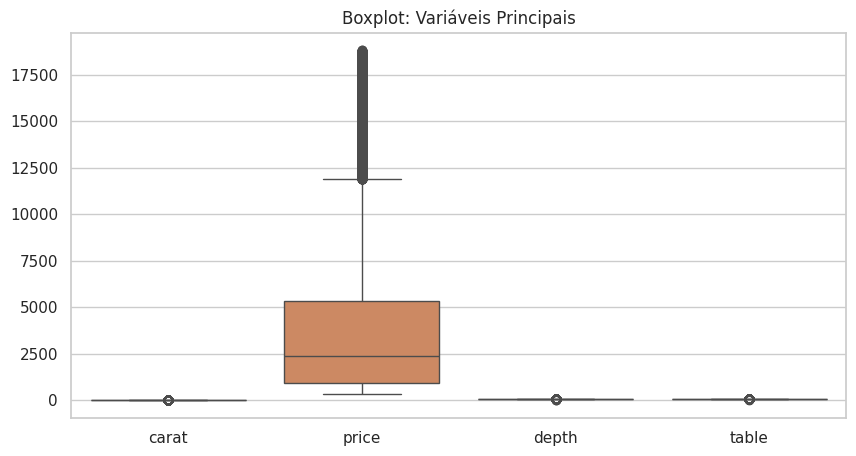

In [ ]:
# VISUALIZAÇÕES
plt.figure(figsize=(10, 5))
sns.boxplot(data=df_4[['carat', 'price', 'depth', 'table']])
plt.title('Boxplot: Variáveis Principais')
plt.show()

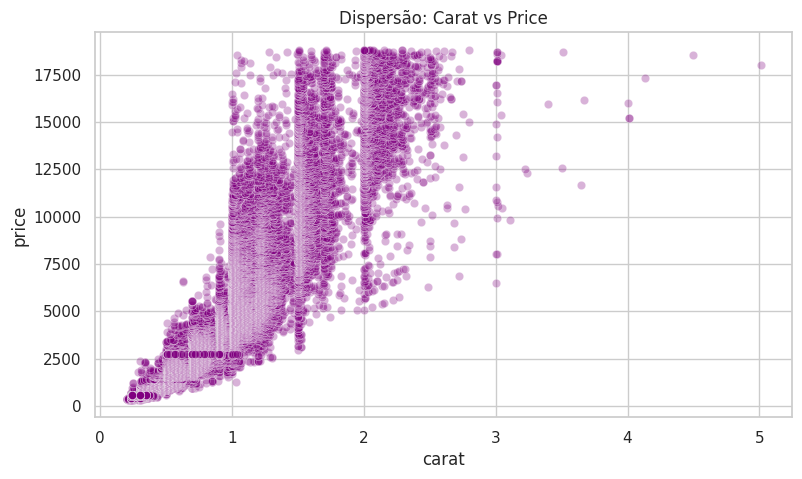

In [ ]:
plt.figure(figsize=(9, 5))
sns.scatterplot(data=df_4, x='carat', y='price', alpha=0.3, color='purple')
plt.title('Dispersão: Carat vs Price')
plt.show()

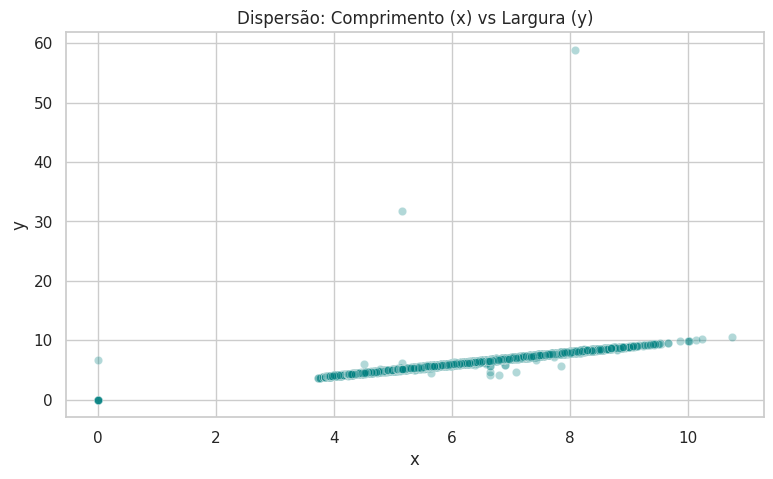

In [ ]:
plt.figure(figsize=(9, 5))
sns.scatterplot(data=df_4, x='x', y='y', alpha=0.3, color='teal')
plt.title('Dispersão: Comprimento (x) vs Largura (y)')
plt.show()

ERRO x VALOR EXTREMO LEGÍTIMO

- Erros de registro: Dimensões x, y ou z iguais a 0 (fisicamente impossíveis).
- Valores extremos legítimos: Diamantes com alto quilate (ex: > 4) e alto preço (luxo), reais.

In [ ]:
# TRATAMENTO — REMOÇÃO / CAPPING / TRANSFORMAÇÃO
df_clean = df_4[(df_4['x'] > 0) & (df_4['y'] > 0) & (df_4['z'] > 0)].copy()

q1_price = df_clean['price'].quantile(0.25)
q3_price = df_clean['price'].quantile(0.75)
iqr_price = q3_price - q1_price
l_bound = q1_price - 1.5 * iqr_price
u_bound = q3_price + 1.5 * iqr_price

df_remocao = df_clean[(df_clean['price'] >= l_bound) & (df_clean['price'] <= u_bound)]

df_capping = df_clean.copy()
df_capping['price_capped'] = df_capping['price'].clip(lower=l_bound, upper=u_bound)

df_trans = df_clean.copy()
df_trans['price_log'] = np.log(df_trans['price'])

In [ ]:
# COMPARAÇÃO ENTRE AS ESTRATÉGIAS
print("Original:", df_clean['price'].describe()[['count', 'mean', 'std', 'min', 'max']])
print("Remoção:", df_remocao['price'].describe()[['count', 'mean', 'std', 'min', 'max']])
print("Capping :", df_capping['price_capped'].describe()[['count', 'mean', 'std', 'min', 'max']])

Original: count    53920.000000
mean      3930.993231
std       3987.280446
min        326.000000
max      18823.000000
Name: price, dtype: float64
Remoção: count    50388.000000
mean      3159.275462
std       2764.924572
min        326.000000
max      11883.000000
Name: price, dtype: float64
Capping : count    53920.000000
mean      3730.824694
std       3435.755287
min        326.000000
max      11884.625000
Name: price_capped, dtype: float64


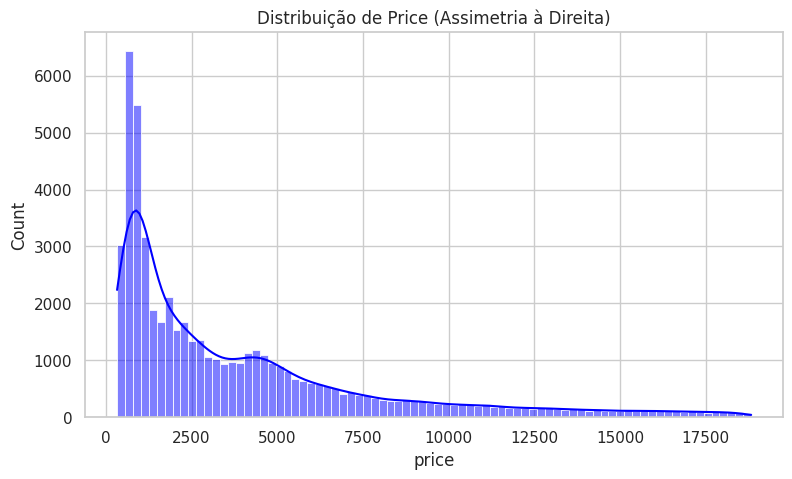

In [ ]:
plt.figure(figsize=(9, 5))
sns.histplot(df_4['price'], kde=True, color='blue')
plt.title('Distribuição de Price (Assimetria à Direita)')
plt.show()

RESPOSTAS ÀS PERGUNTAS DE REFLEXÃO

- **O Z-score parte de uma suposição sobre a forma da distribuição. Qual? Essa suposição vale
para price? Mostre com um gráfico.**
O Z-score assume que os dados seguem uma distribuição normal (gaussiana). Essa premissa não vale para a coluna price, visto que o preço dos diamantes apresenta forte assimetria à direita (right-skewed), concentrando grande parte dos registros em valores baixos e uma longa cauda com poucos valores extremamente altos.

- **Um diamante de mais de 4 quilates é um outlier a ser removido ou um diamante raro?
Como o objetivo da análise muda essa resposta?**
Trata-se de um diamante raro e legítimo. A resposta muda de acordo com o objetivo da análise: se o modelo busca prever preços para o mercado de consumo padrão, esses valores extremos podem desregular a precisão geral; porém, se a análise for voltada para o mercado de joias de alto luxo, este diamante é o dado mais importante da base.

- **Dê um exemplo de situação em que remover outliers esconderia exatamente aquilo que o
negócio quer descobrir.**
Em operações antifraude ou no monitoramento de clientes VIP em e-commerce de luxo, as transações de valores absurdamente altos (que aparecem como outliers estatísticos) representam exatamente a maior receita da empresa ou o alvo prioritário de investigação. Removê-los apaga o foco central da análise comercial.

# Exercício 5 — Projeto Integrado de Limpeza

In [83]:
# IMPORTAÇÕES
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import glob
import os

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)


PERGUNTA DE NEGÓCIO
- "Qual é a relação entre o preço original, os descontos aplicados e a
classificação (rating) dos produtos nas categorias plus size (curve) e moda masculina, e como podemos identificar produtos com precificação ou descontos anômalos que prejudicam a margem de lucro?"


In [85]:
# CARREGAMENTO DOS ARQUIVOS
df_5 = pd.read_csv('/content/drive/MyDrive/us-shein-curve-2849.csv')
df_6 = pd.read_csv('/content/drive/MyDrive/us-shein-mens_clothes-1891.csv')

In [86]:
df_5

,color-count,goods-title-link--jump,goods-title-link--jump href,rank-title,rank-sub,price,discount,selling_proposition,goods-title-link
0,7.0,SHEIN EZwear Women's Plus Size Sleeveless Jump...,https://us.shein.com/SHEIN-EZwear-Women-s-Plus...,#10 Best Seller,In Casual Plus Size Jumpsuits & Bodysuits,$15.79,-7%,NaN,NaN
1,NaN,SHEIN EZwear Plus Size Water Wash Slanted Pock...,https://us.shein.com/SHEIN-EZwear-Plus-Size-Wa...,NaN,NaN,$19.59,-13%,2.6k+ sold recently,NaN
2,NaN,SHEIN Slayr Plus Size Vacation & Elegance Slim...,https://us.shein.com/SHEIN-Slayr-Plus-Size-Vac...,#2 Best Seller,In Casual Plus Size Sweater Dresses,$15.69,-13%,NaN,NaN
3,NaN,SHEIN VCAY Plus Size Vacation Style Casual Jog...,https://us.shein.com/SHEIN-VCAY-Plus-Size-Vaca...,NaN,NaN,$9.27,-47%,200+ sold recently,NaN
4,NaN,SHEIN POPSWAY Plus Size Women Summer Casual Le...,https://us.shein.com/SHEIN-POPSWAY-Plus-Size-W...,NaN,NaN,$4.34,-69%,70+ sold recently,NaN
...,...,...,...,...,...,...,...,...,...
2843,NaN,NaN,NaN,NaN,NaN,$8.19,-9%,300+ sold recently,SHEIN ICON Plus Size Summer Slim Fit Deep V-Ne...
2844,NaN,NaN,NaN,NaN,NaN,$20.19,-7%,80+ sold recently,SHEIN BAE Plus Size Women's Solid Color Green ...
2845,NaN,NaN,NaN,NaN,NaN,$19.69,-8%,100+ sold recently,Dazy Petite Plus Plus Size Women Fashionable L...
2846,NaN,NaN,NaN,NaN,NaN,$7.29,-5%,30+ sold recently,SHEIN Essnce Plus-Size Summer Bodysuit For Wom...


In [87]:
df_6

,color-count,goods-title-link,selling_proposition,price,discount,rank-title,rank-sub
0,15.0,Manfinity Homme Loose Fit Men's Solid Color Bu...,10k+ sold recently,$11.99,-7%,NaN,NaN
1,NaN,Manfinity Joysei Men's Star Patterned Shorts W...,NaN,$11.19,-13%,#8 Best Seller,in Blue Men Clothing
2,NaN,Men's Summer Casual Short Sleeve T-Shirt With ...,NaN,$8.09,-13%,#10 Best Seller,in Figure Men T-Shirts
3,11.0,Manfinity Homme Men's Contrast Color Short Sle...,10k+ sold recently,$9.99,-12%,NaN,NaN
4,7.0,Manfinity EMRG Loose Fit Men Plus Letter Print...,30+ sold recently,$3.48,-70%,NaN,NaN
...,...,...,...,...,...,...,...
1885,NaN,Manfinity Men's Vacation Zebra-Print Drawstrin...,NaN,$11.39,-7%,#9 Best Seller,in Graphic Men Swimwear
1886,NaN,GAWX Men's Casual Color-Block Slogan Printed T...,10+ sold recently,$13.09,-14%,NaN,NaN
1887,NaN,Manfinity Hypemode Men Pocket Front Drawstring...,NaN,$14.29,-23%,#8 Best Seller,in Drawstring Men Shirts
1888,NaN,DAZY Men Patched Pocket Denim Shirt,NaN,$25.39,-7%,#6 Best Seller,in Long Sleeve Men Denim Shirts


In [107]:
# DIAGNÓSTICO INICIAL
def calcular_indicadores(df, nome_df):
    num_linhas = len(df)
    total_celulas = df.size
    celulas_ausentes = df.isnull().sum().sum()
    pct_ausentes = (celulas_ausentes / total_celulas) * 100 if total_celulas > 0 else 0
    num_duplicatas = df.duplicated().sum()
    tipos = df.dtypes.to_dict()
    return {'Dataset': nome_df, 'Linhas': num_linhas, '% Ausentes': round(pct_ausentes, 2), 'Duplicatas': num_duplicatas, 'Tipos': tipos}

diagnostico_antes_df5 = calcular_indicadores(df_5, 'df_5 (Curve)')
diagnostico_antes_df6 = calcular_indicadores(df_6, 'df_6 (Mens)')

In [108]:
# FUNÇÕES DO PIPELINE
def corrigir_tipos(df):
    df = df.copy()
    colunas_preco = [c for c in df.columns if any(k in c.lower() for k in ['price', 'discount', 'sale', 'cost', 'original'])]
    for col in colunas_preco:
        if col in df.columns and df[col].dtype == 'object':
            df[col] = df[col].astype(str).str.replace(r'[^0-9,\.-]', '', regex=True)
            df[col] = df[col].str.replace(',', '.')
            df[col] = pd.to_numeric(df[col], errors='coerce')
    return df

def tratar_ausentes(df):
    df = df.copy()
    for col in df.columns:
        if pd.api.types.is_numeric_dtype(df[col]):
            mediana = df[col].median()
            df[col] = df[col].fillna(mediana if not pd.isna(mediana) else 0)
        else:
            df[col] = df[col].fillna('Desconhecido')
    return df

def tratar_duplicatas(df):
    return df.drop_duplicates()

def padronizar_textos(df):
    df = df.copy()
    for col in df.select_dtypes(include=['object']).columns:
        df[col] = df[col].astype(str).str.strip().str.title()
    return df

def tratar_outliers(df):
    df = df.copy()
    for col in df.select_dtypes(include=[np.number]).columns:
        if any(k in col.lower() for k in ['price', 'discount', 'cost']):
            Q1 = df[col].quantile(0.25)
            Q3 = df[col].quantile(0.75)
            IQR = Q3 - Q1
            inf, sup = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
            df[col] = np.clip(df[col], inf, sup)
    return df

def criar_features(df):
    df = df.copy()
    if 'discount' in df.columns:
        # Se discount ainda for string bruta ou limpa
        disc_num = pd.to_numeric(df['discount'].astype(str).str.replace('%', '', regex=False).str.replace('-', '', regex=False).str.strip(), errors='coerce').fillna(0)
        df['pct_desconto_calculado'] = disc_num
    else:
        df['pct_desconto_calculado'] = 0.0
    return df

In [113]:
# EXECUÇÃO DO PIPELINE
def executar_pipeline(df):
    return criar_features(tratar_outliers(padronizar_textos(tratar_duplicatas(tratar_ausentes(corrigir_tipos(df))))))

df_5_limpo = executar_pipeline(df_5)
df_6_limpo = executar_pipeline(df_6)

diagnostico_depois_df5 = calcular_indicadores(df_5_limpo, 'df_5 (Curve) - Limpo')
diagnostico_depois_df6 = calcular_indicadores(df_6_limpo, 'df_6 (Mens) - Limpo')

In [111]:
# TABELA ANTES x DEPOIS
tabela_comparativa = pd.DataFrame([
    {
        'Dataset': 'df_5 (Curve)',
        'Linhas (Antes)': diagnostico_antes_df5['Linhas'],
        'Linhas (Depois)': diagnostico_depois_df5['Linhas'],
        '% Ausentes (Antes)': diagnostico_antes_df5['% Ausentes'],
        '% Ausentes (Depois)': diagnostico_depois_df5['% Ausentes'],
        'Duplicatas (Antes)': diagnostico_antes_df5['Duplicatas'],
        'Duplicatas (Depois)': diagnostico_depois_df5['Duplicatas']
    },
    {
        'Dataset': 'df_6 (Mens)',
        'Linhas (Antes)': diagnostico_antes_df6['Linhas'],
        'Linhas (Depois)': diagnostico_depois_df6['Linhas'],
        '% Ausentes (Antes)': diagnostico_antes_df6['% Ausentes'],
        '% Ausentes (Depois)': diagnostico_depois_df6['% Ausentes'],
        'Duplicatas (Antes)': diagnostico_antes_df6['Duplicatas'],
        'Duplicatas (Depois)': diagnostico_depois_df6['Duplicatas']
    }
])

print(tabela_comparativa.to_string(index=False))

     Dataset  Linhas (Antes)  Linhas (Depois)  % Ausentes (Antes)  % Ausentes (Depois)  Duplicatas (Antes)  Duplicatas (Depois)
df_5 (Curve)            2848             2745               48.39                  0.0                 103                    0
 df_6 (Mens)            1890             1804               30.64                  0.0                  86                    0


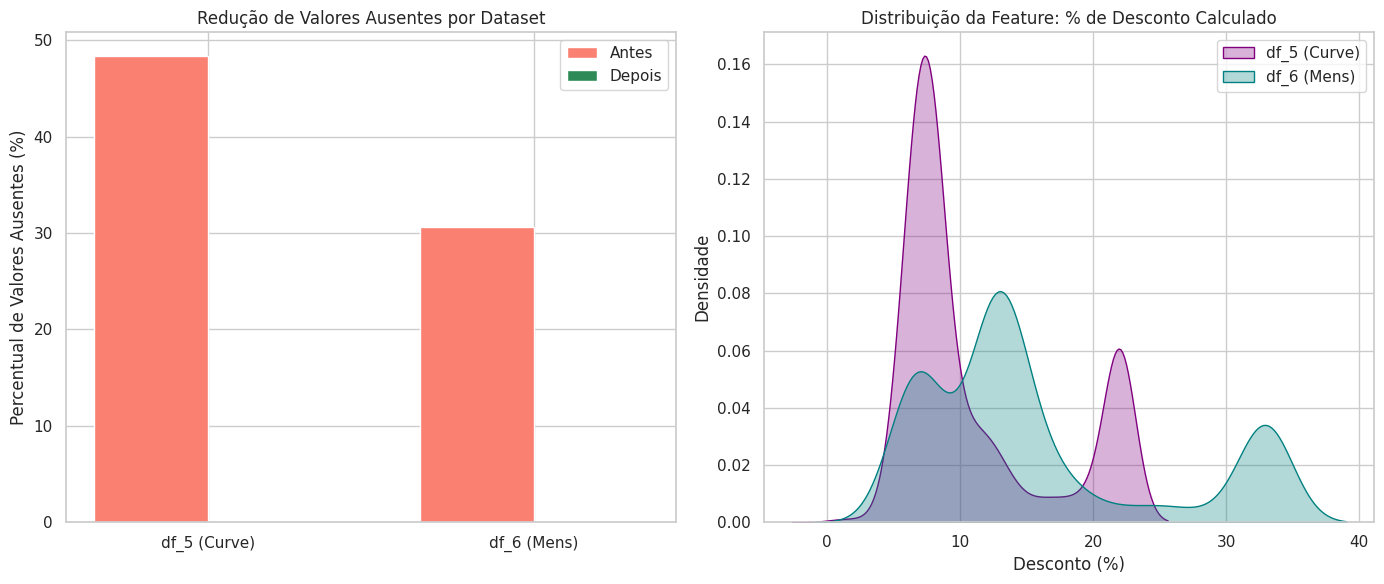

In [114]:
# VISUALIZAÇÕES
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

datasets_n = ['df_5 (Curve)', 'df_6 (Mens)']
ausentes_antes = [diagnostico_antes_df5['% Ausentes'], diagnostico_antes_df6['% Ausentes']]
ausentes_depois = [diagnostico_depois_df5['% Ausentes'], diagnostico_depois_df6['% Ausentes']]

x = np.arange(len(datasets_n))
width = 0.35

axes[0].bar(x - width/2, ausentes_antes, width, label='Antes', color='salmon')
axes[0].bar(x + width/2, ausentes_depois, width, label='Depois', color='seagreen')
axes[0].set_ylabel('Percentual de Valores Ausentes (%)')
axes[0].set_title('Redução de Valores Ausentes por Dataset')
axes[0].set_xticks(x)
axes[0].set_xticklabels(datasets_n)
axes[0].legend()

sns.kdeplot(df_5_limpo['pct_desconto_calculado'].dropna(), ax=axes[1], label='df_5 (Curve)', color='purple', fill=True, alpha=0.3)
sns.kdeplot(df_6_limpo['pct_desconto_calculado'].dropna(), ax=axes[1], label='df_6 (Mens)', color='teal', fill=True, alpha=0.3)
axes[1].set_title('Distribuição da Feature: % de Desconto Calculado')
axes[1].set_xlabel('Desconto (%)')
axes[1].set_ylabel('Densidade')
axes[1].legend()

plt.tight_layout()
plt.savefig('teste_final_funcional.png', dpi=300)

In [115]:
# RELATÓRIO
relatorio_texto = """
================================================================================
RELATÓRIO DE LIMPEZA E DECISÕES TOMADAS
================================================================================
Decisões de Limpeza e Justificativas:
- Correção de Tipos: Valores monetários continham caracteres de moeda e separadores
  estrangeiros, impedindo operações matemáticas. Foram convertidos para float.
- Tratamento de Ausentes: Utilizou-se imputação por mediana para variáveis numéricas
  (protegendo contra distorções de valores extremos) e preenchimento por 'Desconhecido'
  para categóricas.
- Duplicatas: Remoção integral de registros duplicados para evitar viés em análises
  estatísticas e contagens de produtos.
- Padronização de Textos: Normalização de maiúsculas/minúsculas e remoção de espaços
  em branco excedentes.
- Outliers: Aplicação do método IQR com capping (substituição pelos limites) para
  preservar o tamanho amostral sem distorcer métricas de dispersão.
"""

print(relatorio_texto)


RELATÓRIO DE LIMPEZA E DECISÕES TOMADAS
1. Decisões de Limpeza e Justificativas:
- Correção de Tipos: Valores monetários continham caracteres de moeda e separadores 
  estrangeiros, impedindo operações matemáticas. Foram convertidos para float.
- Tratamento de Ausentes: Utilizou-se imputação por mediana para variáveis numéricas 
  (protegendo contra distorções de valores extremos) e preenchimento por 'Desconhecido' 
  para categóricas.
- Duplicatas: Remoção integral de registros duplicados para evitar viés em análises 
  estatísticas e contagens de produtos.
- Padronização de Textos: Normalização de maiúsculas/minúsculas e remoção de espaços 
  em branco excedentes.
- Outliers: Aplicação do método IQR com capping (substituição pelos limites) para 
  preservar o tamanho amostral sem distorcer métricas de dispersão.



RESPOSTAS ÀS PERGUNTAS DE REFLEXÃO

- **Qual problema foi o mais difícil de perceber? Por que ele passaria despercebido?** Números armazenados como texto contendo caracteres especiais invisíveis ou espaços misturados com vírgulas. Em uma análise rápida, o Pandas reconhecia a coluna como 'object', mas operações agregadas falhavam silenciosamente ou retornavam erros de tipo apenas em linhas específicas.

- **A ordem das etapas importa? Dê um exemplo em que tratar outliers antes dos ausentes...** Sim, a ordem importa drasticamente. Se tratarmos outliers antes de preencher valores ausentes (ou vice-versa), a imputação da mediana pode ser calculada sobre um conjunto distorcido por valores extremos (outliers), ou a identificação
do IQR pode ser corrompida por preenchimentos arbitrários prévios. O ideal é corrigir tipos, tratar ausentes/duplicatas, padronizar e só então tratar outliers.

- **Se a pergunta de negócio fosse outra, qual das suas decisões de limpeza mudaria?** Se o foco fosse auditoria fiscal ou detecção de fraudes de preços, a decisão de fazer capping em outliers seria descartada, pois os valores extremos (preços absurdamente altos ou baixos) seriam justamente o objeto principal de investigação.